# European option pricing

1. Closed-form Black-Scholes-Merton price (benchmark)
2. Monte Carlo estimator

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.european import bs_price

In [3]:
# Same parameters as the GBM notebook
S0, K, r, q, sigma, T = 100.0, 100.0, 0.05, 0.02, 0.20, 1.0

In [5]:
call = bs_price(S0, K, r, q, sigma, T, "call")
put = bs_price(S0, K, r, q, sigma, T, "put")

print(f"European call : {call:.4f}")
print(f"European put  : {put:.4f}")

European call : 9.2270
European put  : 6.3301


In [9]:
# Put-call parity: C - P = S0 e^{-qT} - K e^{-rT}
lhs = call - put
rhs = S0 * np.exp(-q * T) - K * np.exp(-r * T)

print(f"C - P                  : {lhs:.6f}")
print(f"S0 e^-qT - K e^-rT     : {rhs:.6f}")
print(f" Parity hols           :", np.isclose(lhs, rhs))

C - P                  : 2.896925
S0 e^-qT - K e^-rT     : 2.896925
 Parity hols           : True


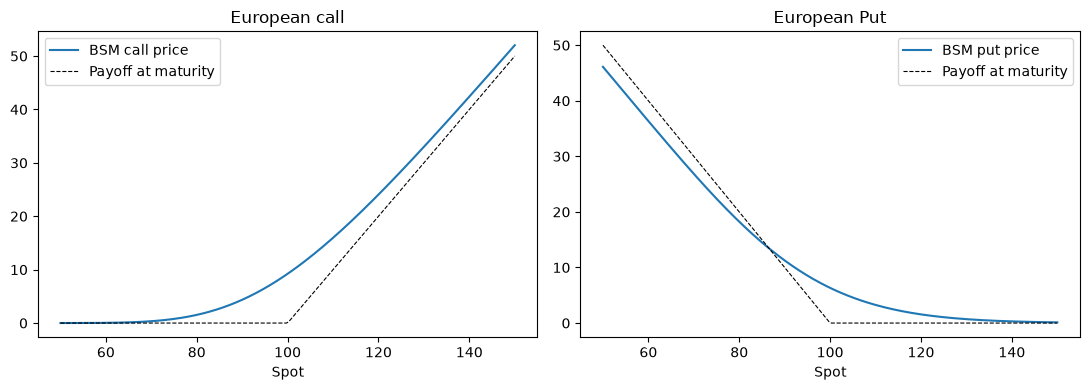

In [10]:
spots = np.linspace(50, 150, 200)
calls = bs_price(spots, K, r, q, sigma, T, "call")
puts = bs_price(spots, K, r, q, sigma, T, "put")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(spots, calls, label="BSM call price")
ax[0].plot(spots, np.maximum(spots - K, 0), "k--", lw=0.8, label="Payoff at maturity")
ax[0].set_title("European call")
ax[0].set_xlabel("Spot")
ax[0].legend()

ax[1].plot(spots, puts, label="BSM put price")
ax[1].plot(spots, np.maximum(K - spots, 0), "k--", lw=0.8, label="Payoff at maturity")
ax[1].set_title("European Put")
ax[1].set_xlabel("Spot")
ax[1].legend()

plt.tight_layout()
plt.savefig("../figures/european_bsm_prices.png", dpi=150)
plt.show()